# Spam detection with NLP - executed experiment notebook

DLBAIPNLP01 - Project: NLP, Task 2 (Text Classification for Spam Detection).
The notebook runs every step of the system: data collection, preprocessing,
encoding, training, evaluation from small to large data sets, cross-corpus
generalisation, final model selection and classification of new messages.
All functions are imported from the `src/` package of the repository.

In [1]:
import sys, platform, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np, pandas as pd, sklearn, nltk, matplotlib
from IPython.display import Image, display
pd.set_option("display.width", 120); pd.set_option("display.max_colwidth", 70)

import data, preprocess, models, experiments
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__,
      "| NLTK", nltk.__version__, "| pandas", pd.__version__, "| NumPy", np.__version__)
print("Machine:", platform.machine(), platform.system())

Python 3.13.16 | scikit-learn 1.9.1 | NLTK 3.10.3 | pandas 3.0.5 | NumPy 2.5.3
Machine: x86_64 Linux


## 1. Data collection

Two public labelled corpora are downloaded automatically: the SMS Spam
Collection (small scenario) and Enron-Spam (large scenario). Exact duplicate
texts are removed before splitting so that no message can appear in both the
training and the test set.

In [2]:
sms_raw, enron_raw = data.load_sms(dedupe=False), data.load_enron(dedupe=False)
sms, enron = data.load_sms(), data.load_enron()
stats = pd.DataFrame({"SMS": data.describe(sms), "Enron e-mail": data.describe(enron)}).T
stats.insert(0, "raw messages", [len(sms_raw), len(enron_raw)])
stats.insert(1, "duplicates removed", [len(sms_raw) - len(sms), len(enron_raw) - len(enron)])
print(stats.to_string())

              raw messages  duplicates removed  messages     spam      ham  spam_share  median_tokens  mean_tokens
SMS                   5574                 403    5171.0    653.0   4518.0      0.1263           12.0         15.4
Enron e-mail         33665                3203   30462.0  14552.0  15910.0      0.4777          154.0        306.0


In [3]:
print("Example SMS messages:")
print(sms.groupby("label").head(3)[["label", "text"]].to_string(index=False))

Example SMS messages:
 label                                                                                                                                                          text
     0                                               Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
     0                                                                                                                                 Ok lar... Joking wif u oni...
     1   Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
     0                                                                                                             U dun say so early hor... U c already then say...
     1           FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £

In [4]:
corpora = {"sms": experiments.split(sms), "enron": experiments.split(enron)}
for name, (tr, te) in corpora.items():
    print(f"{name:6s} train={len(tr):6d} (spam {tr.label.mean():.3f})  "
          f"test={len(te):5d} (spam {te.label.mean():.3f})")

sms    train=  4136 (spam 0.126)  test= 1035 (spam 0.127)
enron  train= 24369 (spam 0.478)  test= 6093 (spam 0.478)


## 2. Preprocessing

Five cumulative preprocessing levels: `raw` (lower-case only), `clean`
(placeholder tokens for URLs, e-mail addresses, phone numbers, currency and
numbers; punctuation removed), `stopwords` (+ NLTK English stop-word removal),
`stem` (+ Porter stemming) and `lemma` (+ WordNet lemmatising).

In [5]:
example = sms[sms.label == 1].text.iloc[0]
print("Original :", example)
for mode in preprocess.MODES:
    print(f"{mode:9s}:", preprocess.preprocess(example, mode))

Original : Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
raw      : free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005. text fa to 87121 to receive entry question(std txt rate)t&c's apply 08452810075over18's
clean    : free entry in tok_num a wkly comp to win fa cup final tkts st may tok_num text fa to tok_phone to receive entry question std txt rate t c s apply over s
stopwords: free entry tok_num wkly comp win fa cup final tkts st may tok_num text fa tok_phone receive entry question std txt rate apply
stem     : free entri tok_num wkli comp win fa cup final tkt st may tok_num text fa tok_phone receiv entri question std txt rate appli


lemma    : free entry tok_num wkly comp win fa cup final tkts st may tok_num text fa tok_phone receive entry question std txt rate apply


In [6]:
# Preprocess every message once per level (cached for the experiments below).
import shutil
shutil.rmtree(experiments.CACHE, ignore_errors=True)
for mode in preprocess.MODES:
    t0 = time.perf_counter()
    for name, (tr, te) in corpora.items():
        experiments.cached_preprocess(pd.concat([tr, te]), name, mode)
    print(f"{mode:9s} preprocessed both corpora in {time.perf_counter() - t0:6.1f} s")

raw       preprocessed both corpora in    2.9 s


clean     preprocessed both corpora in   10.4 s


stopwords preprocessed both corpora in   10.5 s


stem      preprocessed both corpora in   59.3 s


lemma     preprocessed both corpora in   36.6 s


In [7]:
# Encoding: unigram + bigram TF-IDF (or Bag-of-Words counts), min_df = 2.
X_tr, y_tr, X_te, y_te = experiments.prepared(corpora, "lemma")["sms"]
vec = models.make_vectorizer("tfidf").fit(X_tr)
M = vec.transform(X_tr)
print("SMS vocabulary size:", len(vec.vocabulary_), "| training matrix:", M.shape,
      f"| non-zero share: {M.nnz / (M.shape[0] * M.shape[1]):.5f}")

SMS vocabulary size: 5901 | training matrix: (4136, 5901) | non-zero share: 0.00174


## 3. Experiment E1 - effect of each preprocessing step

Every preprocessing level x encoding (BoW, TF-IDF) x classifier (Naive Bayes,
linear SVM, logistic regression) is trained on the training split and scored
on the fixed test split of each corpus.

In [8]:
classic = ["naive_bayes", "linear_svm", "logistic_regression"]
t0 = time.perf_counter()
e1 = experiments.e1_preprocessing(corpora, classic, quick=False)
e1.to_csv(experiments.RESULTS / "e1_preprocessing.csv", index=False)
experiments.plot_preprocessing(e1)
print(f"E1 finished in {time.perf_counter() - t0:.0f} s")

  E1 sms   raw       bow   naive_bayes          F1=0.9412


  E1 sms   raw       bow   linear_svm           F1=0.9187


  E1 sms   raw       bow   logistic_regression  F1=0.9280


  E1 sms   raw       tfidf naive_bayes          F1=0.9402


  E1 sms   raw       tfidf linear_svm           F1=0.9328


...

  E1 enron lemma     bow   logistic_regression  F1=0.9846


  E1 enron lemma     tfidf naive_bayes          F1=0.9871


  E1 enron lemma     tfidf linear_svm           F1=0.9913


  E1 enron lemma     tfidf logistic_regression  F1=0.9908


E1 finished in 737 s


model                            linear_svm  logistic_regression  naive_bayes
corpus vectorizer preprocessing                                              
enron  bow        clean              0.9821               0.9858       0.9819
                  lemma              0.9798               0.9846       0.9838
                  raw                0.9808               0.9851       0.9833
                  stem               0.9777               0.9841       0.9842
                  stopwords          0.9806               0.9853       0.9845
       tfidf      clean              0.9916               0.9904       0.9878
                  lemma              0.9913               0.9908       0.9871
                  raw                0.9916               0.9913       0.9880
                  stem               0.9908               0.9906       0.9868
                  stopwords          0.9913               0.9904       0.9880
sms    bow        clean              0.9524               0.9565

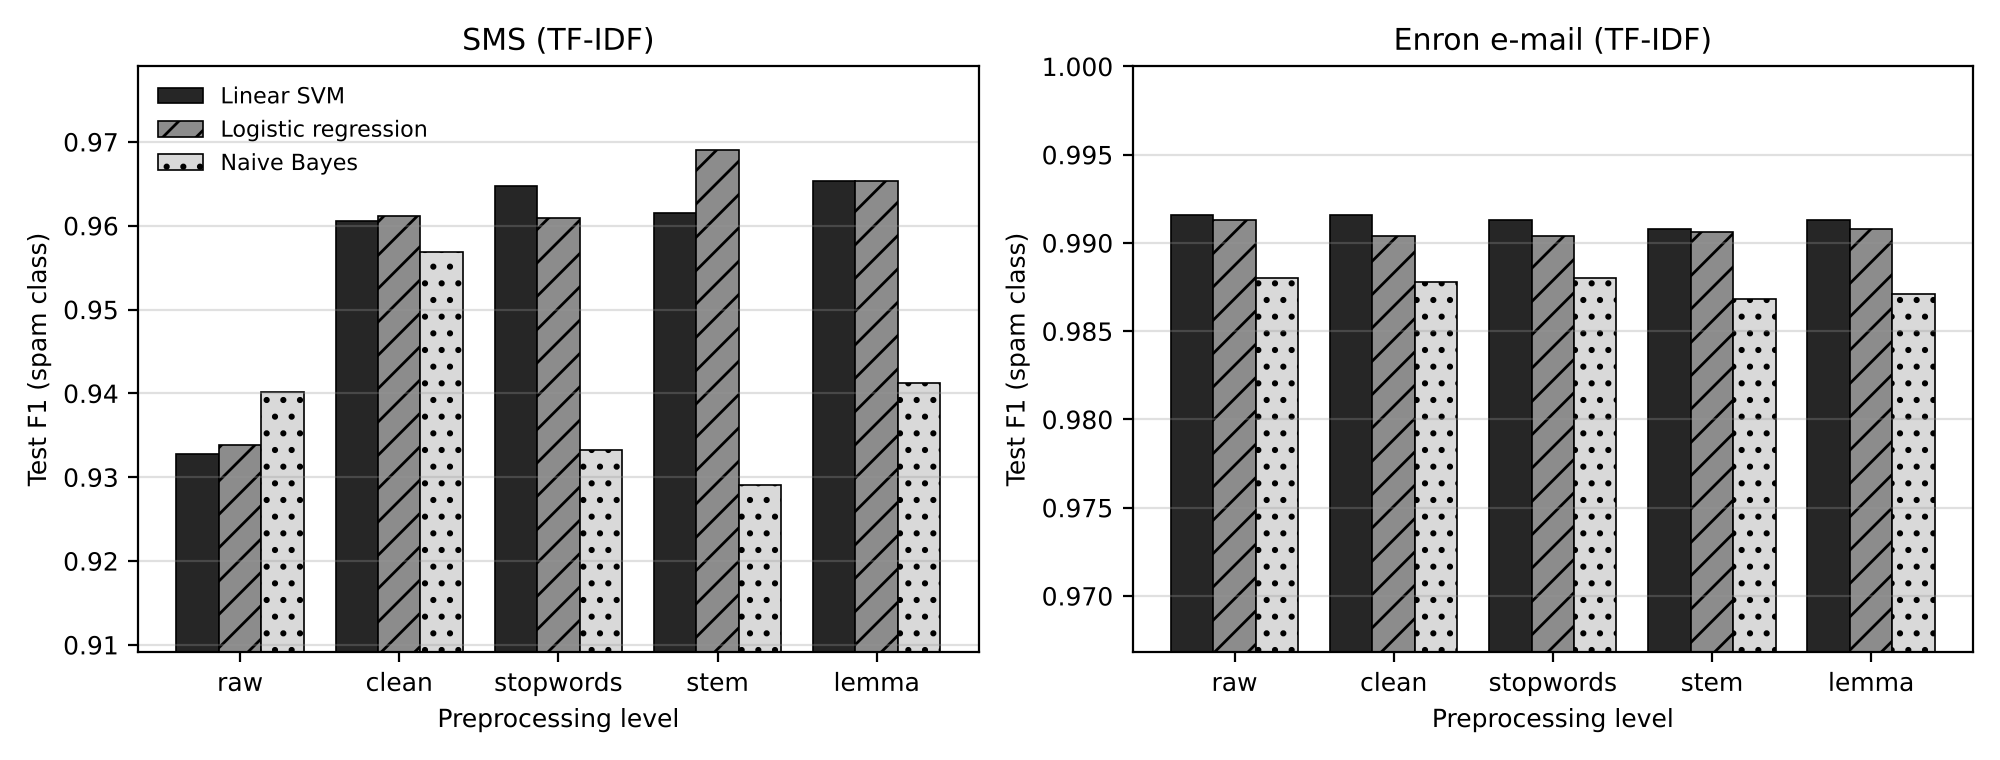

In [9]:
print(e1.pivot_table(index=["corpus", "vectorizer", "preprocessing"], columns="model",
                     values="f1").round(4).to_string())
print()
print("Mean F1 by encoding:")
print(e1.groupby(["corpus", "vectorizer"]).f1.mean().round(4).to_string())
display(Image(str(experiments.FIGURES / "preprocessing_ablation.png"), width=800))

## 4. Experiment E2 - from small to large training sets

Models are trained on stratified random subsets of the training split (five
different subsets per size) and always scored on the same full test split.

In [10]:
t0 = time.perf_counter()
e2_runs, e2 = experiments.e2_learning_curve(corpora, classic, quick=False)
e2_runs.to_csv(experiments.RESULTS / "e2_learning_curve_runs.csv", index=False)
e2.to_csv(experiments.RESULTS / "e2_learning_curve.csv", index=False)
experiments.plot_learning_curves(e2)
print(f"E2 finished in {time.perf_counter() - t0:.0f} s")

  E2 sms   n=   100 done


  E2 sms   n=   250 done


  E2 sms   n=   500 done


  E2 sms   n=  1000 done


  E2 sms   n=  2000 done


...

  E2 enron n=  5000 done


  E2 enron n= 10000 done


  E2 enron n= 20000 done


  E2 enron n= 24369 done


E2 finished in 767 s


corpus  train_size               model  accuracy_mean  f1_mean  f1_std  false_positive_rate_mean
 enron         100          linear_svm         0.9214   0.9182  0.0150                    0.0785
 enron         100 logistic_regression         0.9246   0.9210  0.0112                    0.0713
 enron         100         naive_bayes         0.9267   0.9205  0.0131                    0.0399
 enron         500          linear_svm         0.9665   0.9655  0.0019                    0.0475
 enron         500 logistic_regression         0.9657   0.9647  0.0030                    0.0491
 enron         500         naive_bayes         0.9687   0.9669  0.0007                    0.0195
 enron        1000          linear_svm         0.9743   0.9735  0.0006                    0.0366
 enron        1000 logistic_regression         0.9727   0.9719  0.0010                    0.0398
 enron        1000         naive_bayes         0.9775   0.9762  0.0019                    0.0157
 enron        2500          li

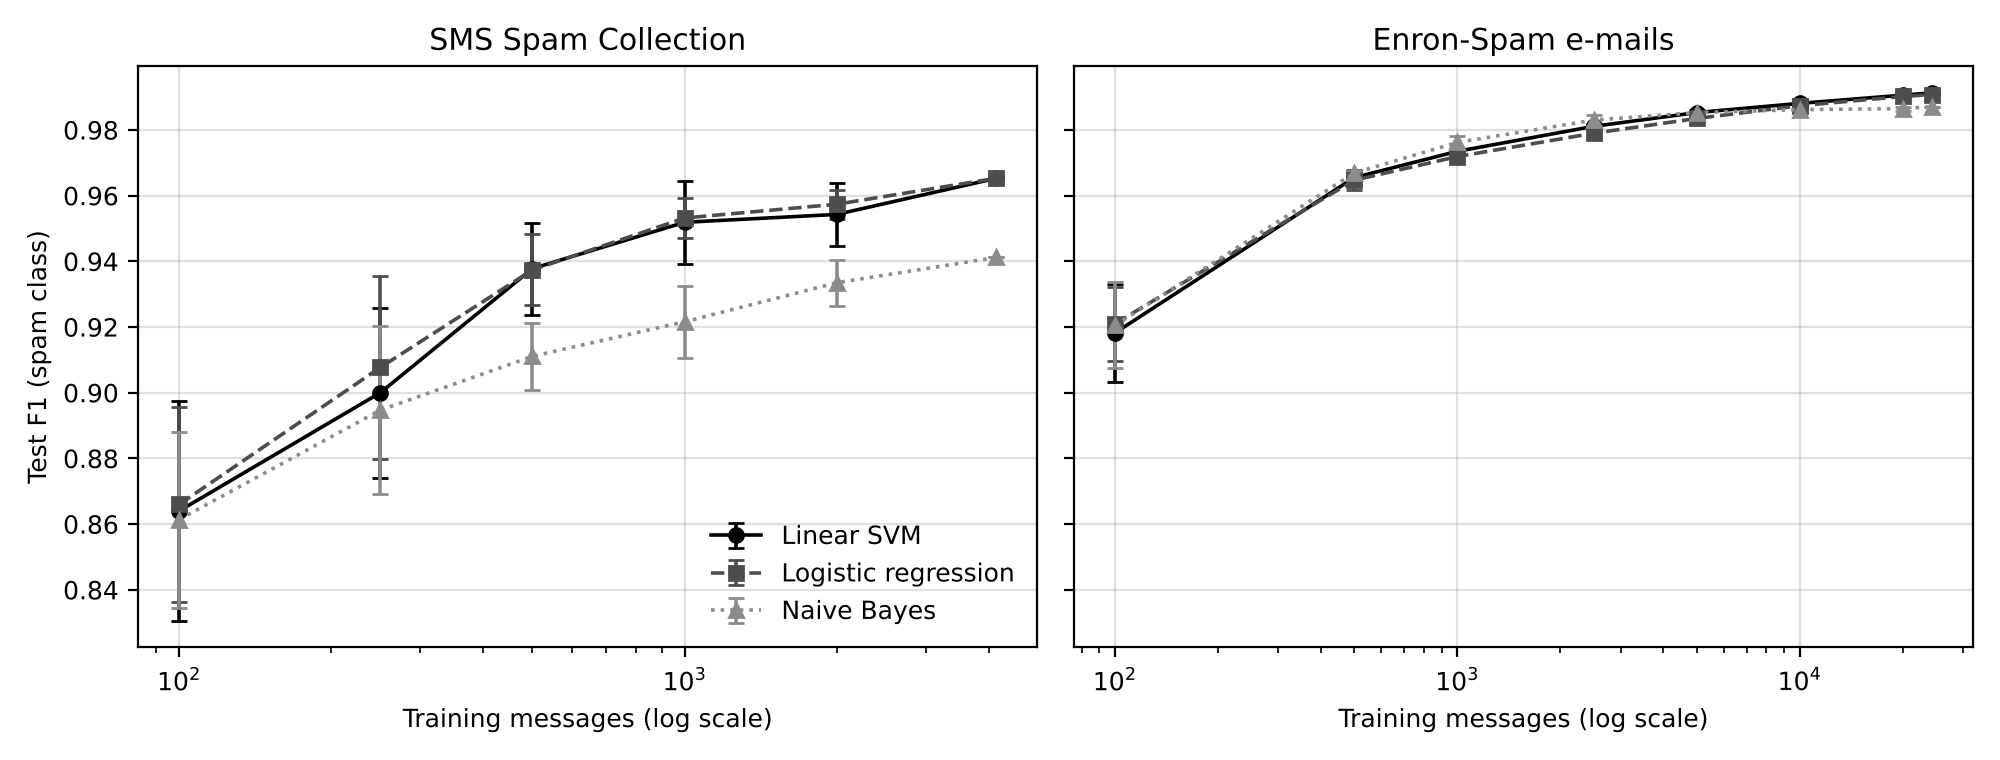

In [11]:
cols = ["corpus", "train_size", "model", "accuracy_mean", "f1_mean", "f1_std",
        "false_positive_rate_mean"]
print(e2[cols].to_string(index=False))
display(Image(str(experiments.FIGURES / "learning_curves.png"), width=800))

## 5. Experiment E3 - model comparison including a neural network

Lemmatised text and TF-IDF features; 5-fold stratified cross-validation on the
training split plus one evaluation on the held-out test split. `mlp` is a
feed-forward neural network with one hidden layer of 64 units.

In [12]:
t0 = time.perf_counter()
e3 = experiments.e3_models(corpora, classic + ["mlp"])
e3.to_csv(experiments.RESULTS / "e3_models.csv", index=False)
print(f"E3 finished in {time.perf_counter() - t0:.0f} s")
print(e3[["corpus", "model", "cv_f1_mean", "cv_f1_std", "test_accuracy", "test_precision",
          "test_recall", "test_f1", "test_roc_auc", "test_train_seconds"]].to_string(index=False))

  E3 sms   naive_bayes          cvF1=0.9402 testF1=0.9412


  E3 sms   linear_svm           cvF1=0.9448 testF1=0.9653


  E3 sms   logistic_regression  cvF1=0.9459 testF1=0.9653


  E3 sms   mlp                  cvF1=0.9220 testF1=0.9482


  E3 enron naive_bayes          cvF1=0.9873 testF1=0.9871


  E3 enron linear_svm           cvF1=0.9902 testF1=0.9913


  E3 enron logistic_regression  cvF1=0.9891 testF1=0.9908


  E3 enron mlp                  cvF1=0.9894 testF1=0.9897
E3 finished in 868 s
corpus               model  cv_f1_mean  cv_f1_std  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc  test_train_seconds
   sms         naive_bayes      0.9402     0.0182         0.9855          0.9677       0.9160   0.9412        0.9937                0.17
   sms          linear_svm      0.9448     0.0171         0.9913          0.9766       0.9542   0.9653        0.9978                0.19
   sms logistic_regression      0.9459     0.0174         0.9913          0.9766       0.9542   0.9653        0.9975                0.15
   sms                 mlp      0.9220     0.0247         0.9874          0.9917       0.9084   0.9482        0.9944                4.63
 enron         naive_bayes      0.9873     0.0014         0.9877          0.9870       0.9873   0.9871        0.9989               15.98
 enron          linear_svm      0.9902     0.0008         0.9916          0.9877       0.9948   0.9

## 6. Experiment E4 - generalisation across message types

The best classifier from E3 (by mean cross-validated F1) is trained on SMS
only, e-mail only, and both corpora combined, and tested on both test sets.

In [13]:
best = e3.groupby("model")["cv_f1_mean"].mean().idxmax()
print("Best model by mean CV F1:", best)
e4 = experiments.e4_generalisation(corpora, best)
e4.to_csv(experiments.RESULTS / "e4_generalisation.csv", index=False)
print(e4[["trained_on", "tested_on", "accuracy", "precision", "recall", "f1",
          "false_positive_rate"]].to_string(index=False))

Best model by mean CV F1: linear_svm


  E4 train=sms      test=sms   F1=0.9653


  E4 train=sms      test=enron F1=0.4807


  E4 train=enron    test=sms   F1=0.2495


  E4 train=enron    test=enron F1=0.9913


  E4 train=combined test=sms   F1=0.8522


  E4 train=combined test=enron F1=0.9830
trained_on tested_on  accuracy  precision  recall     f1  false_positive_rate
       sms       sms    0.9913     0.9766  0.9542 0.9653               0.0033
       sms     enron    0.5444     0.5277  0.4414 0.4807               0.3614
     enron       sms    0.3140     0.1448  0.9008 0.2495               0.7710
     enron     enron    0.9916     0.9877  0.9948 0.9913               0.0113
  combined       sms    0.9585     0.7750  0.9466 0.8522               0.0398
  combined     enron    0.9839     0.9920  0.9742 0.9830               0.0072


## 7. Final system: model selection and held-out evaluation

For each channel (SMS, e-mail) the preprocessing level and classifier are
selected by cross-validation on the training split only. The selected pipeline
is refitted on the full training split, evaluated once on the test split, and
saved to `models/`.

In [14]:
import train
sys.argv = ["train.py"]
t0 = time.perf_counter()
train.main()
print(f"Final training finished in {time.perf_counter() - t0:.0f} s")

  sms   clean     naive_bayes          cv F1=0.9600


  sms   clean     linear_svm           cv F1=0.9588


  sms   clean     logistic_regression  cv F1=0.9564


  sms   stopwords naive_bayes          cv F1=0.9473


  sms   stopwords linear_svm           cv F1=0.9466


...

  email lemma     naive_bayes          cv F1=0.9869


  email lemma     linear_svm           cv F1=0.9899


  email lemma     logistic_regression  cv F1=0.9890
email: selected {'mode': 'clean', 'model': 'linear_svm', 'cv_f1': 0.9908}


email: test {'accuracy': 0.992, 'precision': 0.9887, 'recall': 0.9945, 'f1': 0.9916, 'false_positive_rate': 0.0104, 'tp': 2895, 'fp': 33, 'tn': 3149, 'fn': 16, 'roc_auc': 0.9994}


saved models -> /home/claude/spam-detector/models
Final training finished in 591 s


channel                      sms       email
model                naive_bayes  linear_svm
preprocessing              clean       clean
cv_f1                       0.96      0.9908
accuracy                  0.9894       0.992
precision                 0.9839      0.9887
recall                    0.9313      0.9945
f1                        0.9569      0.9916
roc_auc                   0.9963      0.9994
false_positive_rate       0.0022      0.0104
tp                           122        2895
fp                             2          33
tn                           902        3149
fn                             9          16
predict_ms                 0.047       0.859


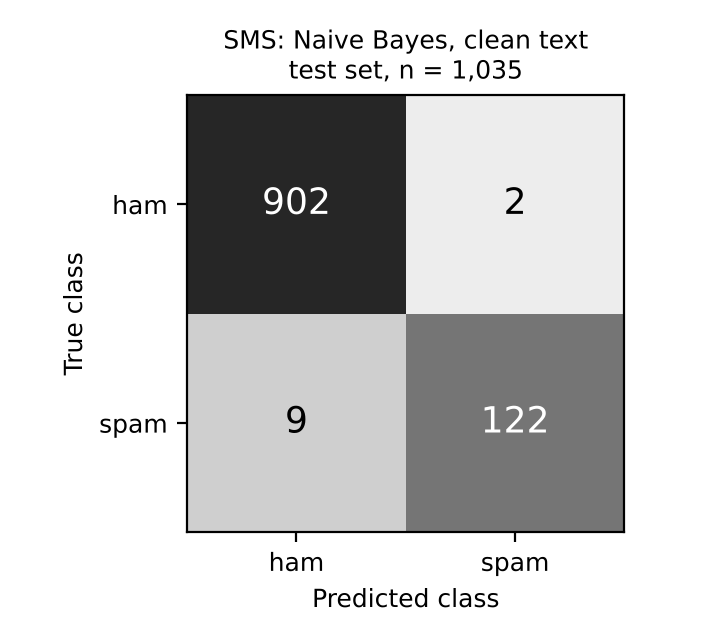

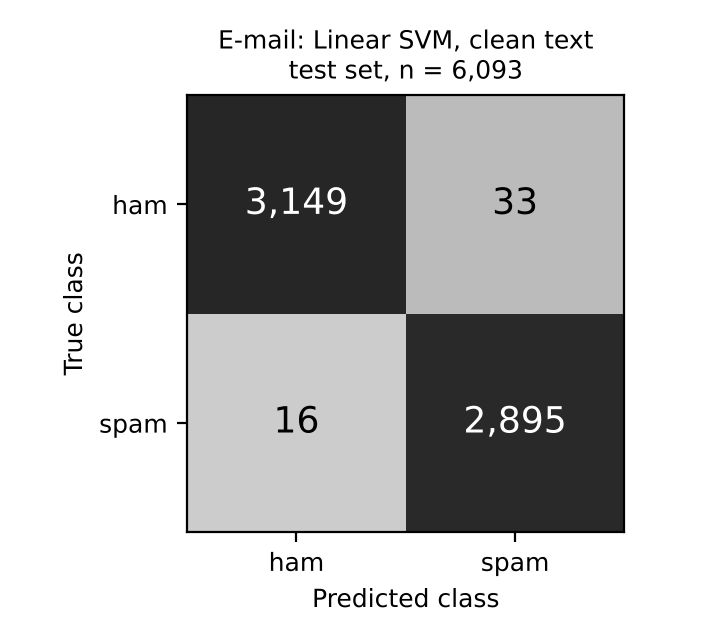

In [15]:
final = json.loads((ROOT / "results" / "final_model.json").read_text())
rows = []
for ch, r in final.items():
    rows.append({"channel": ch, "model": r["selected"]["model"], "preprocessing": r["selected"]["mode"],
                 "cv_f1": r["selected"]["cv_f1"], **{k: r["test"][k] for k in
                 ["accuracy", "precision", "recall", "f1", "roc_auc", "false_positive_rate",
                  "tp", "fp", "tn", "fn"]},
                 "predict_ms": r["predict_ms_per_message"]})
print(pd.DataFrame(rows).T.to_string(header=False))
for ch in final:
    display(Image(str(experiments.FIGURES / f"confusion_final_{ch}.png"), width=300))

## 8. Error analysis

Misclassified test messages of the final SMS model, and the n-grams that the
final e-mail model weights most strongly towards each class.

In [16]:
import joblib
sms_model = joblib.load(ROOT / "models" / "sms_classifier.joblib")
_, sms_te = corpora["sms"]
pred = sms_model.predict(sms_te.text.tolist())
err = sms_te.assign(pred=pred)[pred != sms_te.label.to_numpy()]
# Sexually explicit spam texts are counted but not printed.
EXPLICIT = ("sex", "xxx", "babe", "bitch", "shit", "nasty", "rude", "cum", "hot")
def show(texts):
    clean = [t for t in texts if not any(w in t.lower() for w in EXPLICIT)]
    for t in clean: print("  -", t[:110])
    if len(clean) < len(texts): print(f"  ({len(texts) - len(clean)} explicit message(s) not printed)")
print(f"False positives (ham flagged as spam): {(err.label == 0).sum()}")
show(err[err.label == 0].text.tolist())
print(f"False negatives (spam missed): {(err.label == 1).sum()}")
show(err[err.label == 1].text.tolist())

False positives (ham flagged as spam): 2
  - Nokia phone is lovly..
  - Unlimited texts. Limited minutes.
False negatives (spam missed): 9
  - Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, F
  - Missed call alert. These numbers called but left no message. 07008009200
  - In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-B
  - Latest News! Police station toilet stolen, cops have nothing to go on!
  (5 explicit message(s) not printed)


In [17]:
email_model = joblib.load(ROOT / "models" / "email_classifier.joblib")
names = email_model.named_steps["vectorize"].get_feature_names_out()
coef = email_model.named_steps["classify"].coef_.ravel()
order = np.argsort(coef)
print("Strongest spam indicators:", ", ".join(names[order[::-1][:15]]))
print("Strongest ham indicators :", ", ".join(names[order[:15]]))

nb_ = sms_model.named_steps["classify"]; v = sms_model.named_steps["vectorize"].get_feature_names_out()
ratio = nb_.feature_log_prob_[1] - nb_.feature_log_prob_[0]
print("SMS model, highest spam/ham log-probability ratio:", ", ".join(v[np.argsort(ratio)[::-1][:15]]))

Strongest spam indicators: your, http, remove, no, software, here, hello, you, re tok_num, sex, site, life, online, viagra, account
Strongest ham indicators : enron, vince, louise, thanks, attached, energy, doc, daren, i, gas, dave, enron com, employees, houston, the
SMS model, highest spam/ham log-probability ratio: to tok_phone, claim, prize, tok_phone, call tok_phone, tok_phone now, your mobile, nokia, have won, tok_num cash, tok_num prize, to claim, guaranteed, tok_phone to, tok_url


## 9. Classifying new messages

The saved pipelines accept raw text. Short texts are routed to the SMS model,
long or multi-line texts to the e-mail model.

In [18]:
from predict import classify
new_messages = [
    "URGENT! Your mobile number has won a 2000 pound prize. Call 09061743810 to claim now",
    "hey, running 10 min late, can you order me a coffee?",
    "Are you free for a call about the budget tomorrow at 3?",
    "FREE entry! Win cash and a holiday, txt WIN to 80086 today",
    "Subject: lowest prices on meds\nBuy cheap medication online without prescription. "
    "Limited offer, click here to order now and save 80 percent.",
    "Subject: schedule for thursday\nHi Sally, please find attached the revised schedule "
    "for the pipeline meeting. Let me know if the volumes look right. Thanks",
]
for r in classify(new_messages):
    print(f"{r['label'].upper():4s} [{r['channel']:5s}] score={r['score']:+7.3f}  {r['message'][:70]!r}")

SPAM [sms  ] score=+14.055  'URGENT! Your mobile number has won a 2000 pound prize. Call 0906174381'
HAM  [sms  ] score= -5.164  'hey, running 10 min late, can you order me a coffee?'
HAM  [sms  ] score= -3.156  'Are you free for a call about the budget tomorrow at 3?'
SPAM [sms  ] score= +7.256  'FREE entry! Win cash and a holiday, txt WIN to 80086 today'
SPAM [email] score= +1.908  'Subject: lowest prices on meds\nBuy cheap medication online without pre'
HAM  [email] score= -2.447  'Subject: schedule for thursday\nHi Sally, please find attached the revi'


## 10. Automated tests

In [19]:
import subprocess
out = subprocess.run([sys.executable, "-m", "pytest", "-q", str(ROOT / "tests")],
                     capture_output=True, text=True, cwd=ROOT)
print(out.stdout[-600:])

.......................                                                  [100%]
23 passed in 10.35s

